In [3]:
from google.colab import files
uploaded = files.upload()  # select cancer-risk-factors.csv from your computer

import pandas as pd
df_prime = pd.read_csv("cancer-risk-factors.csv")
print(df_prime["Cancer_Type"].value_counts())

Saving cancer-risk-factors.csv to cancer-risk-factors.csv
Cancer_Type
Lung        527
Breast      460
Colon       418
Prostate    305
Skin        290
Name: count, dtype: int64


count    2000.000000
mean       63.248000
std        10.462946
min        25.000000
25%        56.000000
50%        64.000000
75%        70.000000
max        90.000000
Name: Age, dtype: float64
Min age: 25
Max age: 90
Median age: 64.0


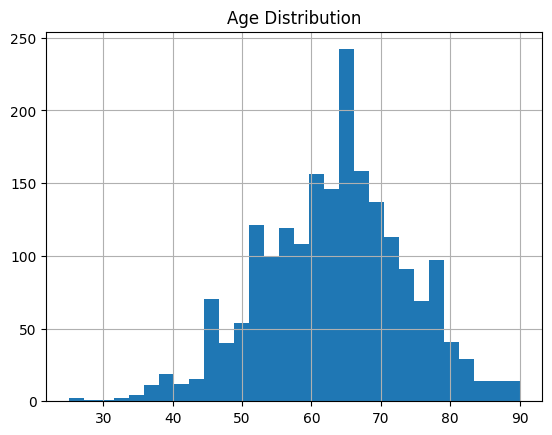

In [ ]:
import matplotlib.pyplot as plt

print(df["Age"].describe())
print(f"Min age: {df['Age'].min()}")
print(f"Max age: {df['Age'].max()}")
print(f"Median age: {df['Age'].median()}")


df["Age"].hist(bins=30)
plt.title("Age Distribution")
plt.show()

In [ ]:
print(df.columns.tolist())

['Patient_ID', 'Cancer_Type', 'Age', 'Gender', 'Smoking', 'Alcohol_Use', 'Obesity', 'Family_History', 'Diet_Red_Meat', 'Diet_Salted_Processed', 'Fruit_Veg_Intake', 'Physical_Activity', 'Air_Pollution', 'Occupational_Hazards', 'BRCA_Mutation', 'H_Pylori_Infection', 'Calcium_Intake', 'Overall_Risk_Score', 'BMI', 'Physical_Activity_Level', 'Risk_Level']


In [2]:
import pandas as pd

df = pd.read_csv("cancer-risk-factors-extended-1.csv")
print(df["Cancer_Type"].value_counts())

Cancer_Type
Lung        1471
Breast      1173
Colon       1110
Prostate     910
Skin         836
Name: count, dtype: int64


=== Shape ===
Original: (2000, 21)
Extended: (5500, 21)

=== Cancer Type Distribution ===
Original:
Cancer_Type
Lung        527
Breast      460
Colon       418
Prostate    305
Skin        290
Name: count, dtype: int64

Extended:
Cancer_Type
Lung        1471
Breast      1173
Colon       1110
Prostate     910
Skin         836
Name: count, dtype: int64

=== Risk Level Distribution (proportions) ===
Original:
Risk_Level
Medium    0.787
Low       0.162
High      0.051
Name: proportion, dtype: float64

Extended:
Risk_Level
Medium    0.795
Low       0.151
High      0.054
Name: proportion, dtype: float64

=== Statistical Comparison ===
Feature                    Orig Mean   Ext Mean    Orig SD     Ext SD
----------------------------------------------------------------------
Age                           63.248     63.483     10.463     10.750
Gender                         0.489      0.488      0.500      0.500
Smoking                        5.157      5.343      3.325      3.368
Alcohol_Use  

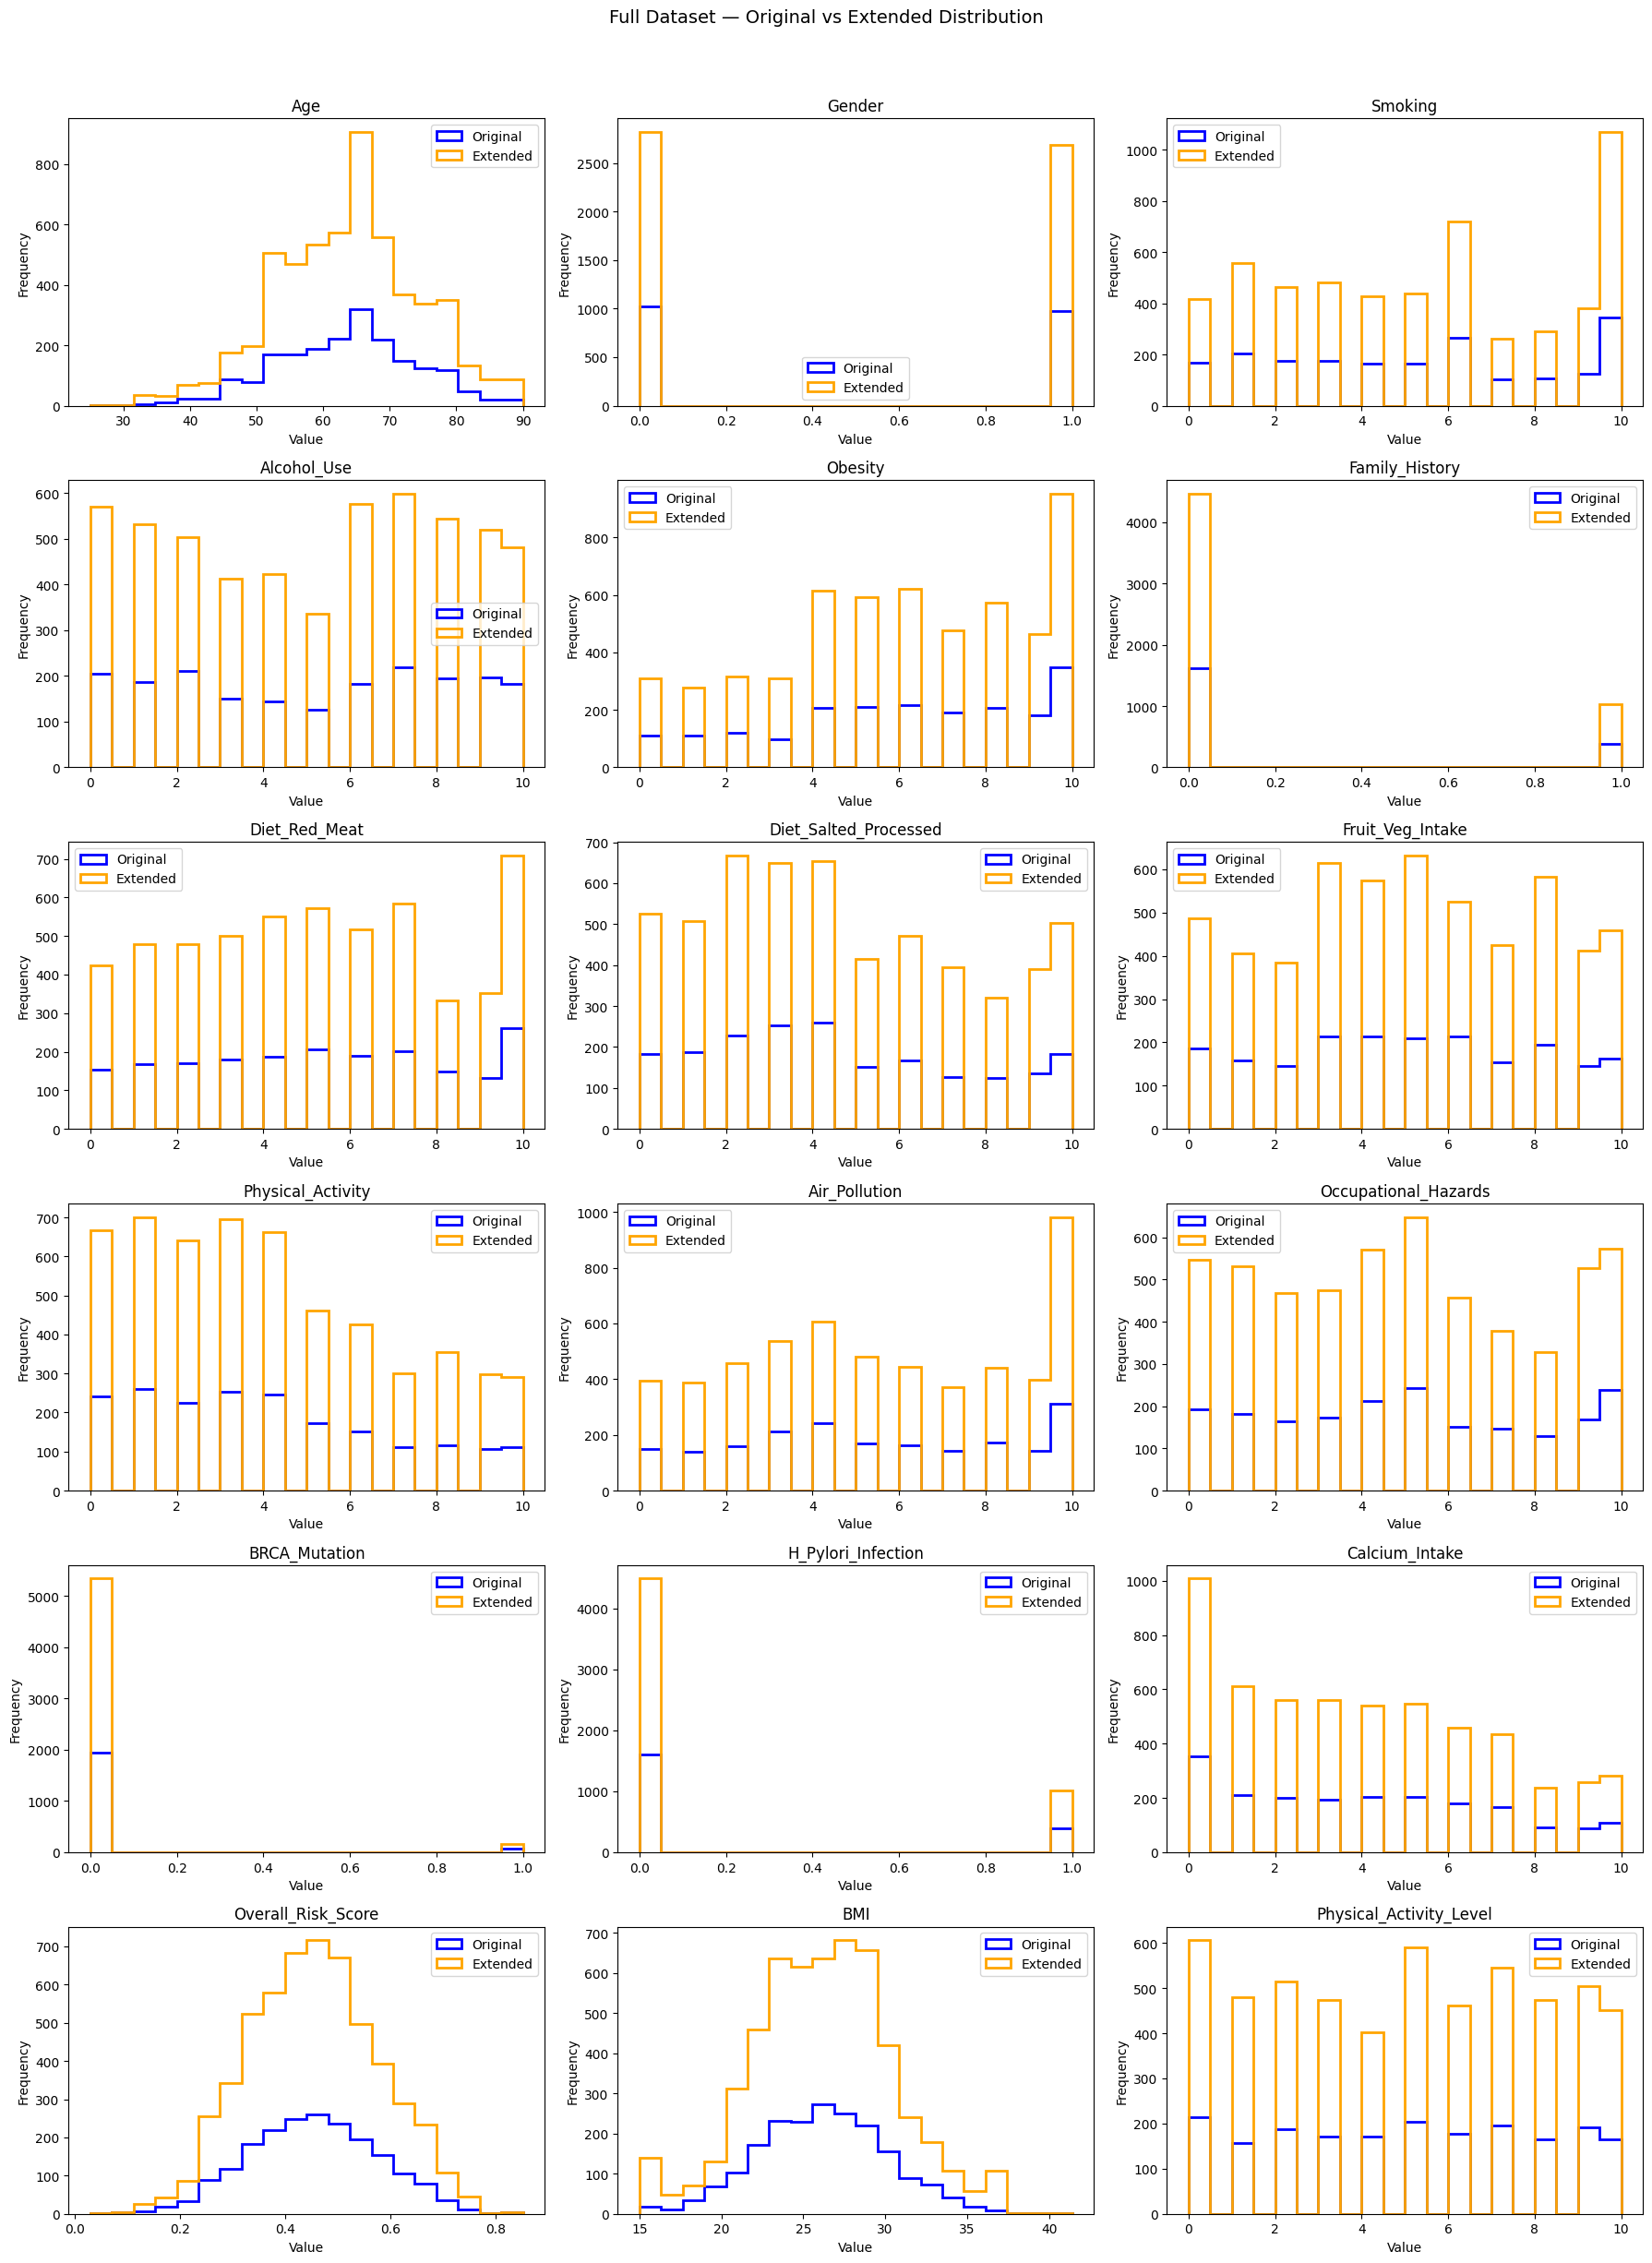

Saved full_dataset_comparison.png


In [6]:
# Visual Representation
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ks_2samp

# Load both
df_original = pd.read_csv("cancer-risk-factors.csv")
df_extended = pd.read_csv("cancer-risk-factors-extended-1.csv")

print("=== Shape ===")
print(f"Original: {df_original.shape}")
print(f"Extended: {df_extended.shape}")

# Cancer Type
print("\n=== Cancer Type Distribution ===")
print("Original:")
print(df_original["Cancer_Type"].value_counts())
print("\nExtended:")
print(df_extended["Cancer_Type"].value_counts())

# Risk Level
print("\n=== Risk Level Distribution (proportions) ===")
print("Original:")
print(df_original["Risk_Level"].value_counts(normalize=True).round(3))
print("\nExtended:")
print(df_extended["Risk_Level"].value_counts(normalize=True).round(3))

# Numeric columns
num_cols = [
    "Age", "Gender", "Smoking", "Alcohol_Use", "Obesity",
    "Family_History", "Diet_Red_Meat", "Diet_Salted_Processed",
    "Fruit_Veg_Intake", "Physical_Activity", "Air_Pollution",
    "Occupational_Hazards", "BRCA_Mutation", "H_Pylori_Infection",
    "Calcium_Intake", "Overall_Risk_Score", "BMI",
    "Physical_Activity_Level"
]

# Statistical comparison
print("\n=== Statistical Comparison ===")
print(f"{'Feature':<25} {'Orig Mean':>10} {'Ext Mean':>10} {'Orig SD':>10} {'Ext SD':>10}")
print("-" * 70)
for col in num_cols:
    print(f"{col:<25} "
          f"{df_original[col].mean():>10.3f} "
          f"{df_extended[col].mean():>10.3f} "
          f"{df_original[col].std():>10.3f} "
          f"{df_extended[col].std():>10.3f}")

# KS Test
print("\n=== KS Test (p > 0.05 = similar) ===")
for col in num_cols:
    stat, p = ks_2samp(df_original[col], df_extended[col])
    status = "✓ similar" if p > 0.05 else "✗ different"
    print(f"{col:<25} p={p:.4f}  {status}")

# Histograms
n_cols = 3
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    combined = pd.concat([df_original[col], df_extended[col]])
    bins = np.linspace(combined.min(), combined.max(), 21)

    axes[i].hist(df_original[col], bins=bins, alpha=1.0,
                 color='blue', label='Original',
                 histtype='step', linewidth=2)
    axes[i].hist(df_extended[col], bins=bins, alpha=1.0,
                 color='orange', label='Extended',
                 histtype='step', linewidth=2)
    axes[i].set_title(col)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Full Dataset — Original vs Extended Distribution",
             fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("full_dataset_comparison.png", bbox_inches='tight', dpi=150)
plt.show()
print("Saved full_dataset_comparison.png")

In [8]:
#checking for similarity across classes
import pandas as pd
import numpy as np
from scipy.stats import ks_2samp

num_cols = [
    "Age", "Gender", "Smoking", "Alcohol_Use", "Obesity",
    "Family_History", "Diet_Red_Meat", "Diet_Salted_Processed",
    "Fruit_Veg_Intake", "Physical_Activity", "Air_Pollution",
    "Occupational_Hazards", "BRCA_Mutation", "H_Pylori_Infection",
    "Calcium_Intake", "Overall_Risk_Score", "BMI",
    "Physical_Activity_Level"
]

for risk_class in ["Low", "Medium", "High"]:
    orig_class = df_original[df_original["Risk_Level"] == risk_class]
    ext_class  = df_extended[df_extended["Risk_Level"] == risk_class]

    print(f"\n{'='*60}")
    print(f"CLASS: {risk_class} | Original: {len(orig_class)} | Extended: {len(ext_class)}")
    print(f"{'='*60}")
    print(f"{'Feature':<25} {'Orig Mean':>10} {'Ext Mean':>10} {'p-value':>10} {'Status':>10}")
    print("-" * 60)

    for col in num_cols:
        orig_vals = orig_class[col].dropna()
        ext_vals  = ext_class[col].dropna()

        orig_mean = orig_vals.mean()
        ext_mean  = ext_vals.mean()

        stat, p = ks_2samp(orig_vals, ext_vals)
        status = "✓" if p > 0.05 else "✗"

        print(f"{col:<25} {orig_mean:>10.3f} {ext_mean:>10.3f} {p:>10.4f} {status:>10}")


CLASS: Low | Original: 324 | Extended: 833
Feature                    Orig Mean   Ext Mean    p-value     Status
------------------------------------------------------------
Age                           63.685     63.801     0.9699          ✓
Gender                         0.494      0.528     0.9343          ✓
Smoking                        2.846      3.354     0.0186          ✗
Alcohol_Use                    2.985      3.619     0.0175          ✗
Obesity                        4.824      5.205     0.3174          ✓
Family_History                 0.139      0.142     1.0000          ✓
Diet_Red_Meat                  3.972      4.218     0.8638          ✓
Diet_Salted_Processed          2.889      3.496     0.0109          ✗
Fruit_Veg_Intake               5.667      5.388     0.3985          ✓
Physical_Activity              3.670      3.842     0.9880          ✓
Air_Pollution                  2.948      3.493     0.0416          ✗
Occupational_Hazards           3.364      3.922     0.0

In [ ]:
# Check Overall_Risk_Score distribution for High class
synthetic = df_extended[len(df_original):]  # synthetic rows only

synthetic_high = synthetic[synthetic["Risk_Level"] == "High"]

print(f"Total synthetic High:            {len(synthetic_high)}")
print(f"Synthetic High with score >0.60: {(synthetic_high['Overall_Risk_Score'] > 0.60).sum()}")
print(f"Synthetic High with score >0.63: {(synthetic_high['Overall_Risk_Score'] > 0.63).sum()}")
print(f"Synthetic High with score >0.66: {(synthetic_high['Overall_Risk_Score'] > 0.66).sum()}")
print(f"Synthetic High with score >0.70: {(synthetic_high['Overall_Risk_Score'] > 0.70).sum()}")

print(f"\nOverall_Risk_Score distribution for synthetic High:")
print(synthetic_high["Overall_Risk_Score"].describe())

# Also check what proportion of synthetic High actually meets the threshold
total = len(synthetic_high)
above_60 = (synthetic_high['Overall_Risk_Score'] > 0.60).sum()
print(f"\n{above_60}/{total} = {above_60/total*100:.1f}% of synthetic High have score > 0.60")

Total synthetic High:            541
Synthetic High with score >0.60: 121
Synthetic High with score >0.63: 102
Synthetic High with score >0.66: 64
Synthetic High with score >0.70: 22

Overall_Risk_Score distribution for synthetic High:
count    541.000000
mean       0.465564
std        0.141277
min        0.151260
25%        0.351198
50%        0.460051
75%        0.573708
max        0.756109
Name: Overall_Risk_Score, dtype: float64

121/541 = 22.4% of synthetic High have score > 0.60
